Рекомендации фильмов на завтра

Кому предложить фильм, который стал популярным за неделю? Если зритель часто выбирает детективы, можно поднять свежий детектив выше общего хита. Проверим эту идею на данных курса. Ещё два списка кандидатов дадут матричная факторизация и нейросеть. Бустинг получит три оценки и историю зрителя на момент рекомендации.

Финальный результат — файл `recommendations.parquet`. В нём одна строка на пользователя, а столбцы от `rank_1` до `rank_10` содержат исходные идентификаторы фильмов в порядке показа.

## 1. Данные и календарь эксперимента

Понадобятся Python 3.10+, NumPy, pandas, SciPy, PyTorch, CatBoost, PyArrow, Matplotlib и threadpoolctl. Если их нет в текущем ядре, выполните `%pip install numpy pandas scipy torch catboost pyarrow matplotlib threadpoolctl` в отдельной ячейке и перезапустите ядро. На CPU код выполняет те же вычисления. Видеокарта ускоряет обучение нейросети и поиск top-N.

Четыре CSV можно положить рядом с ноутбуком, в его папку `data` или в `Datasets/recsys_course_final` в корне диска проекта. Для другой папки задайте переменную `RECSYS_DATA_DIR`. Если их нет, следующая ячейка скачает файлы по ссылкам преподавателя. Контрольная сумма защищает от неполной загрузки и HTML-страницы вместо CSV.

In [1]:
import hashlib
import os
import shutil
from pathlib import Path
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow as pa
import pyarrow.parquet as pq
import torch
from torch import nn
from torch.nn import functional as F
from scipy import sparse
from catboost import CatBoostClassifier, Pool
from threadpoolctl import threadpool_limits
from IPython.display import display

SEED = 42
N, K = 20, 10
BATCH = 512
VALID_DAYS = 10
THREADS = min(4, os.cpu_count() or 1)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(THREADS)
torch.manual_seed(SEED)
if DEVICE.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = False

project = Path.cwd()
if (project / 'final' / 'RecSys_HW3.ipynb').is_file():
    project = project / 'final'
output_file = project / 'recommendations.parquet'
files = {
    'train.csv': ('1-CcS22-UpTJeNcFlA0dVLrEQn8jnI0d-', '5190cc7c89f6719ce93520c7cab566a2e882442ab4ae201f13b05b7fa46d2c52'),
    'test.csv': ('11iz3xDh0IIoEIBY0dyRSvByY3qfiT3BG', '8399c2a97f4fb55036c28241c9a02d1014eddcdd49401f58cf81bce5db807231'),
    'users.csv': ('1zl2jWMdUhc-IMakHlihQhJ5PGGZm9-_O', '37b2945240628a3f215e1fb5f79b4cff386d8988b21fa61e5b135aef4541182c'),
    'items.csv': ('1chCmpiCKJRjdqNftHc-t2ALl3qbAp2G8', '027c3a0027b4fe4a8db9d5fa626ab40bab507c96aac81d462db0771eb2cb4a8e'),
}

cache = Path.home() / '.cache' / 'recsys_course_final'
locations = [project, project / 'data', Path(project.anchor) / 'Datasets' / 'recsys_course_final', cache]
existing = next((p for p in locations if all((p / name).is_file() for name in files)), cache)
data_dir = Path(os.environ.get('RECSYS_DATA_DIR', existing))
data_dir.mkdir(parents=True, exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda: f.read(2**20), b''):
            h.update(block)
    return h.hexdigest()

for name, (file_id, digest) in files.items():
    path = data_dir / name
    if not path.is_file():
        url = f'https://drive.usercontent.google.com/download?id={file_id}&export=download&confirm=t'
        part = path.with_suffix('.csv.part')
        with urlopen(Request(url, headers={'User-Agent': 'Mozilla/5.0'}), timeout=90) as response, part.open('wb') as out:
            shutil.copyfileobj(response, out)
        if sha256(part) != digest:
            raise ValueError(f'Не удалось скачать {name}. Папка с оригиналами: https://drive.google.com/drive/folders/1HT0Apm8Jft0VPLJtdBBUGu9s1M7vZcoJ')
        part.replace(path)
    elif sha256(path) != digest:
        raise ValueError(f'{path}: контрольная сумма отличается от исходного CSV курса')
print('Датасет:', data_dir.name)
print('Устройство:', DEVICE, '| кандидатов от модели:', N, '| итоговых мест:', K)

Датасет: recsys_course_final
Устройство: cuda | кандидатов от модели: 20 | итоговых мест: 10


В этом проекте «досмотр» означает, что зритель посмотрел больше половины фильма. Так в данных размечен `target = 1`. В исходном CSV колонка называется `watched_pct`. Проверим, как она связана с меткой, и дальше будем читать только дату, идентификаторы и метку. Процент и длительность **текущего** просмотра неизвестны в момент рекомендации.

Одну пару пользователь–фильм датасет описывает одним событием. Поэтому при подборе кандидатов скрываем всё, что зритель уже смотрел, даже если он бросил фильм. Справочники и журналы событий могут содержать разные множества пользователей. Для выдачи возьмём их объединение.

In [2]:
def read_events(name):
    types = {'user_id': 'int32', 'item_id': 'int32', 'target': 'uint8', 'watched_pct': 'float32'}
    parts, mismatches = [], 0
    for chunk in pd.read_csv(data_dir / name, usecols=[*types, 'last_watch_dt'], dtype=types, chunksize=250_000):
        pct = chunk.pop('watched_pct')
        mismatches += ((pct > 50) != chunk.target.astype(bool)).sum()
        chunk['date'] = pd.to_datetime(chunk.pop('last_watch_dt')).to_numpy(dtype='datetime64[D]').astype('int32')
        parts.append(chunk)
    return pd.concat(parts, ignore_index=True), int(mismatches)

train, miss_train = read_events('train.csv')
test, miss_test = read_events('test.csv')
profiles = pd.read_csv(data_dir / 'users.csv', usecols=['user_id'], dtype='int32')
metadata = pd.read_csv(data_dir / 'items.csv', usecols=['item_id', 'title', 'genres', 'content_type', 'release_year'])
assert profiles.user_id.is_unique and metadata.item_id.is_unique
print('Расхождений между target и правилом watched_pct > 50 в train:', miss_train)
def date_text(day_number):
    return str(np.datetime64('1970-01-01') + np.timedelta64(int(day_number), 'D'))

def describe_events(frame, show_target):
    return [len(frame), frame.user_id.nunique(), frame.item_id.nunique(),
            date_text(frame.date.min()), date_text(frame.date.max()), round(frame.target.mean(), 4) if show_target else 'после оценки']

display(pd.DataFrame([describe_events(train, True), describe_events(test, False)], index=['train.csv', 'test.csv'],
                     columns=['события', 'зрители', 'фильмы', 'с', 'по', 'доля target=1']))
assert train.date.max() < test.date.min() and set(train.target.unique()) == {0, 1}
raw_users = np.union1d(profiles.user_id, np.union1d(train.user_id, test.user_id)).astype('int32')
raw_items = np.union1d(metadata.item_id, np.union1d(train.item_id, test.item_id)).astype('int32')
nu, ni = len(raw_users), len(raw_items)
train_user = np.isin(raw_users, train.user_id.unique())
seen_any = np.isin(raw_users, np.union1d(train.user_id.unique(), test.user_id.unique()))
print(f'Для выдачи: {nu:,} зрителей, из них {sum(~seen_any):,} только в профилях.')
print(f'В тесте впервые появились {sum(~np.isin(test.user_id.unique(), train.user_id.unique())):,} зрителей.')

Расхождений между target и правилом watched_pct > 50 в train: 0


,события,зрители,фильмы,с,по,доля target=1
train.csv,4866956,880421,15418,2021-03-13,2021-08-12,0.4397
test.csv,608467,216399,7817,2021-08-13,2021-08-22,после оценки


Для выдачи: 1,058,084 зрителей, из них 95,933 только в профилях.
В тесте впервые появились 81,730 зрителей.


In [3]:
origin = int(train.date.min())
test_start = int(test.date.min()) - origin
valid_start = test_start - VALID_DAYS
tomorrow = int(test.date.max()) - origin + 1
def calendar(day):
    return date_text(origin + day)

events = pd.concat([train, test], ignore_index=True)
if not events.date.is_monotonic_increasing:
    events = events.sort_values('date', kind='stable')
eu = np.searchsorted(raw_users, events.user_id).astype('int32')
ei = np.searchsorted(raw_items, events.item_id).astype('int32')
ey = events.target.to_numpy(dtype='uint8', copy=True)
days = (events.date.to_numpy() - origin).astype('int16')
offset = np.searchsorted(days, np.arange(tomorrow + 1))
assert np.unique(eu.astype('int64') * ni + ei).size == len(eu)
del events, train, test, profiles

def one_day(day):
    s = slice(offset[day], offset[day + 1])
    return eu[s], ei[s], ey[s]

display(pd.DataFrame([[name, calendar(lo), calendar(hi-1), int(offset[hi]-offset[lo])]
                     for name, lo, hi in [('train_stage_1', 0, valid_start),
                                          ('valid_stage_1', valid_start, test_start),
                                          ('test', test_start, tomorrow)]],
                     columns=['отрезок', 'с', 'по', 'события']))
print('Дата финальной рекомендации:', calendar(tomorrow))

,отрезок,с,по,события
0,train_stage_1,2021-03-13,2021-08-02,4318687
1,valid_stage_1,2021-08-03,2021-08-12,548269
2,test,2021-08-13,2021-08-22,608467


Дата финальной рекомендации: 2021-08-23


Последние десять дней исходного train нужны для обучения бустинга. Внутри них отложим последние два дня для выбора числа деревьев. Десять дней официального test оставим для оценки уже выбранной модели. Идентификаторы из обоих файлов нужны для общей нумерации. Обучающие метки и статистики берём только из разрешённого временного среза. Рекомендация на 14 августа, например, может учитывать 13 августа.

Для профиля вкусов выделим у фильма основной жанр. Берём первый содержательный тег из справочника, пропуская общие пометки вроде «зарубежные». Четырнадцать наиболее частых жанров оставляем отдельно, остальные объединяем. Для измерения разнообразия в конце понадобятся **все** жанровые теги.

In [4]:
meta = metadata.set_index('item_id').reindex(raw_items)
title = meta.title.fillna('Без названия').to_numpy()
broad = {'зарубежные', 'русские', 'российские', 'советские', 'фильмы', 'сериалы'}
def genre_tags(text):
    tags = [w.strip().lower() for w in str(text).split(',') if w.strip()]
    return tuple(dict.fromkeys(w for w in tags if w not in broad))
tags = [genre_tags(t) for t in meta.genres.fillna('')]
primary = pd.Series([g[0] if g else 'прочее' for g in tags])
frequent = primary[primary != 'прочее'].value_counts().head(14).index.tolist()
genre_names = frequent + ['прочее']
genre = pd.Categorical(primary.where(primary.isin(frequent), 'прочее'), categories=genre_names).codes.astype('int32')
form = pd.Categorical(meta.content_type.fillna('нет данных')).codes.astype('int32')
years = meta.release_year.fillna(0).to_numpy()
era = np.digitize(years, [1, 1980, 2000, 2010, 2020]).astype('int32')
G = len(genre_names)
print('Основные жанры:', ', '.join(frequent))

Основные жанры: драмы, боевики, мелодрамы, комедии, документальное, для детей, для взрослых, триллеры, семейное, фантастика, криминал, ужасы, фитнес, приключения


## 2. Что известно к утру выбранного дня

В `History` хранятся счётчики пользователя, фильма и трёх пар «пользователь × атрибут фильма». Вызов `advance(d)` обрабатывает только события до начала дня d. Зная только календарный день, нельзя восстановить порядок нескольких просмотров за вечер. В качестве опорного фильма дня берём досмотренный фильм с наименьшим ID, а при отсутствии досмотров — просмотренный с наименьшим ID. Это воспроизводимое правило для равных дат.

In [5]:
class History:
    def __init__(self):
        self.day = 0
        self.u_n = np.zeros(nu, 'int32')
        self.u_pos = np.zeros(nu, 'int32')
        self.i_n = np.zeros(ni, 'int32')
        self.i_pos = np.zeros(ni, 'int32')
        self.last_day = np.full(nu, -1, 'int16')
        self.anchor = np.full(nu, -1, 'int32')
        self.before = np.full(len(eu), -1, 'int32')
        self.daily = np.zeros((tomorrow, ni), 'int32')
        self.counts, self.likes = {}, {}
        for name, attr in [('genre', genre), ('form', form), ('era', era)]:
            shape = (nu, int(attr.max()) + 1)
            self.counts[name] = np.zeros(shape, 'int32')
            self.likes[name] = np.zeros(shape, 'int32')

    def advance(self, stop):
        assert self.day <= stop <= tomorrow
        for d in range(self.day, stop):
            u, i, y = one_day(d)
            self.before[offset[d]:offset[d + 1]] = self.anchor[u]
            self.last_day[u] = d
            self.daily[d] = np.bincount(i, minlength=ni)
            self.i_n += self.daily[d]
            self.i_pos += np.bincount(i[y == 1], minlength=ni).astype('int32')
            np.add.at(self.u_n, u, 1)
            np.add.at(self.u_pos, u, y)
            for name, attr in [('genre', genre), ('form', form), ('era', era)]:
                key = (u, attr[i])
                np.add.at(self.counts[name], key, 1)
                np.add.at(self.likes[name], key, y)
            who, inverse = np.unique(u, return_inverse=True)
            priority = (1 - y.astype('int32')) * (ni + 1) + i
            best = np.full(len(who), 2 * (ni + 1), 'int32')
            np.minimum.at(best, inverse, priority)
            self.anchor[who] = best % (ni + 1)
        self.day = stop

    def matrix(self):
        end = offset[self.day]
        # Единица означает сам просмотр, две дополнительные единицы — положительную метку.
        weight = (1 + 2 * ey[:end]).astype('float32')
        return sparse.csr_matrix((weight, (eu[:end], ei[:end])), shape=(nu, ni))

    def favorites(self, users):
        strength = self.counts['genre'][users] + 2 * self.likes['genre'][users]
        rows = np.arange(len(users))
        first = strength.argmax(axis=1)
        has_first = strength[rows, first] > 0
        strength[rows, first] = -1
        second = strength.argmax(axis=1)
        has_second = strength[rows, second] > 0
        return np.where(has_first, first, G), np.where(has_second, second, G)

history = History()
history.advance(valid_start)
assert history.u_n.sum() == offset[valid_start]
assert history.last_day.max() < valid_start

## 3. Три способа найти кандидатов

**Недельный тренд по жанрам.** Сначала ранжируем фильмы по числу просмотров за последние семь полных дней (TopPopular). Для основного любимого жанра умножаем `просмотры + 1` на 2, для второго — на 1,5. В логарифмах это две прибавки к скору. У нового зрителя обе прибавки равны нулю. Обычный недельный топ понадобится для отдельного сравнения с этой эвристикой.

**Разреженная SVD.** Строки матрицы соответствуют зрителям, столбцы — фильмам. Понижаем вес очень частых фильмов и длинных историй. Ищем 16 главных направлений в пространстве фильмов. Для этого несколько раз умножаем случайный базис на $X^\top X$ блоками строк. В памяти остаётся тонкая матрица с 24 столбцами. Для пользователя восстанавливаем строку как $(x_u V)V^\top$. Свежий просмотр попадёт в $x_u$ уже на следующее утро.

In [6]:
def fit_svd(x, item_count, dim=16):
    scale = (item_count.astype('float32') + 5) ** -0.35
    a = x.copy()
    lengths = np.diff(a.indptr)
    a.data *= scale[a.indices]
    a.data *= np.repeat(1 / np.sqrt(np.maximum(lengths, 1).astype('float32')), lengths)
    basis = np.random.default_rng(SEED).normal(size=(ni, dim + 8)).astype('float32')
    block_size = 65_536
    with threadpool_limits(limits=THREADS):
        for _ in range(4):
            result = np.zeros_like(basis)
            for start in range(0, nu, block_size):
                block = a[start:start + block_size]
                result += block.T @ (block @ basis)
            basis = np.linalg.qr(result, mode='reduced')[0]
        gram = np.zeros((basis.shape[1], basis.shape[1]), 'float32')
        for start in range(0, nu, block_size):
            small = a[start:start + block_size] @ basis
            gram += small.T @ small
        _, directions = np.linalg.eigh(gram)
    vectors = (basis @ directions[:, -dim:]).astype('float32')
    return vectors, scale

**Нейросеть следующего просмотра.** На вход подаём опорный фильм из последнего дня с просмотрами. Сеть учится ставить фильм, который зритель затем досмотрел, выше случайно выбранных кандидатов. Эмбеддинг опорного фильма проходит через небольшой MLP, затем скалярное произведение с эмбеддингом фильма-кандидата даёт скор. Отдельные входные и выходные эмбеддинги позволяют учитывать порядок фильмов. Например, из первого фильма серии можно предсказывать переход ко второму.

Для обучения берём все досмотры, у которых был более ранний день истории. К каждому добавляем четыре случайных фильма с вероятностью, пропорциональной частоте в истории в степени 0,65. Отрицательные примеры для этой задачи — альтернативы конкретному следующему просмотру. Совпавший с целью или опорой фильм исключаем из отрицательной части функции потерь.

In [7]:
class NextFilm(nn.Module):
    def __init__(self, size, dim=24):
        super().__init__()
        self.source = nn.Embedding(size, dim)
        self.encoder = nn.Sequential(nn.Linear(dim, 48), nn.ReLU(), nn.Linear(48, dim))
        self.dest = nn.Embedding(size, dim)
        self.bias = nn.Embedding(size, 1)
        nn.init.normal_(self.dest.weight, std=0.04)
        nn.init.zeros_(self.bias.weight)

    def query(self, anchor):
        return self.encoder(self.source(anchor))

def fit_neural(h, epochs=2):
    torch.manual_seed(SEED)
    end = offset[h.day]
    take = (h.before[:end] >= 0) & (ey[:end] == 1)
    a, b = h.before[:end][take], ei[:end][take]
    known_source = np.bincount(a, minlength=ni) > 0
    known_dest = np.bincount(b, minlength=ni) > 0
    cdf = np.cumsum(h.i_n.astype('float64') ** 0.65)
    slots = (np.arange(131_072) + 0.5) * cdf[-1] / 131_072
    noise = torch.as_tensor(np.searchsorted(cdf, slots), dtype=torch.long, device=DEVICE)
    a = torch.as_tensor(a, dtype=torch.long, device=DEVICE)
    b = torch.as_tensor(b, dtype=torch.long, device=DEVICE)
    model = NextFilm(ni).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.004)
    trace = []
    for _ in range(epochs):
        total = torch.zeros((), device=DEVICE)
        for loc in torch.randperm(len(a), device=DEVICE).split(4096):
            src, dst = a[loc], b[loc]
            neg = noise[torch.randint(len(noise), (len(loc), 4), device=DEVICE)]
            q = model.query(src)
            pos_score = (q * model.dest(dst)).sum(1) + model.bias(dst).squeeze(-1)
            neg_score = (q[:, None] * model.dest(neg)).sum(2) + model.bias(neg).squeeze(-1)
            mask = (neg != dst[:, None]) & (neg != src[:, None])
            loss = F.softplus(-pos_score).mean() + (F.softplus(neg_score) * mask).sum() / mask.sum().clamp_min(1)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            total += loss.detach() * len(loc)
        trace.append(round((total / len(a)).item(), 4))
    with torch.no_grad():
        codes = torch.arange(ni, device=DEVICE)
        q = model.query(codes).cpu().numpy()
        v = model.dest.weight.detach().cpu().numpy()
        bias = model.bias.weight.detach().cpu().numpy().ravel()
    print(f'{calendar(h.day)} | переходов для нейросети: {len(a):,} | loss по эпохам: {trace}')
    return q, v, bias, known_source, known_dest

class FirstLevel:
    def __init__(self, h, x):
        self.cutoff = h.day
        self.v, self.scale = fit_svd(x, h.i_n)
        self.fold = self.scale[:, None] * self.v
        self.svd_known = h.i_n > 0
        self.q, self.w, self.bias, self.src_known, self.dst_known = fit_neural(h)
        self.v_gpu = torch.as_tensor(self.v.T.copy(), device=DEVICE)
        self.w_gpu = torch.as_tensor(self.w.T.copy(), device=DEVICE)
        self.bias_gpu = torch.as_tensor(self.bias, device=DEVICE)

Каждая модель умеет оценить заданную пару и выбрать собственный top-N из доступного каталога. В справочнике нет даты появления фильма на сервисе. Добавляем фильм в доступный каталог утром после первого зарегистрированного просмотра. Для SVD и нейросети дополнительно требуется обученное представление фильма. При отсутствии истории или пригодного представления пользователя подставляем нулевой скор обучаемой модели, а короткий список заполняем недельным топом. Непросмотренные фильмы подбираем отдельно для каждого зрителя.

In [8]:
class Morning:
    """Фиксирует неделю и матрицу просмотренного на одну дату."""
    def __init__(self, h, x, models):
        assert models.cutoff <= h.day and x.nnz == offset[h.day]
        self.date, self.h, self.x, self.m = h.day, h, x, models
        this_week = h.daily[max(0, h.day - 7):h.day].sum(axis=0)
        prev_week = h.daily[max(0, h.day - 14):max(0, h.day - 7)].sum(axis=0)
        self.week = np.log1p(this_week).astype('float32')
        self.growth = self.week - np.log1p(prev_week).astype('float32')
        self.base = torch.as_tensor(self.week, device=DEVICE)
        self.genre = torch.as_tensor(genre, device=DEVICE)
        self.inactive = torch.as_tensor(h.i_n == 0, device=DEVICE)
        self.no_svd = torch.as_tensor(~models.svd_known, device=DEVICE)
        self.no_neural = torch.as_tensor(~models.dst_known, device=DEVICE)

class UserBatch:
    def __init__(self, morning, users):
        h, m = morning.h, morning.m
        assert h.day == morning.date
        self.morning, self.users = morning, np.asarray(users, dtype='int32')
        self.x = morning.x[self.users]
        self.f1, self.f2 = h.favorites(self.users)
        self.z = self.x @ m.fold
        self.z /= np.sqrt(np.maximum(1, np.diff(self.x.indptr)).astype('float32'))[:, None]
        self.has_svd = np.any(self.z != 0, axis=1)
        anchor = h.anchor[self.users]
        self.has_nn = (anchor >= 0) & m.src_known[anchor.clip(min=0)]
        self.q = m.q[anchor.clip(min=0)]
        self.r_seen = np.repeat(np.arange(len(self.users), dtype='int32'), np.diff(self.x.indptr))

    def score_pairs(self, row, item):
        # row — строка пользователя внутри батча, item — внутренний индекс фильма.
        a, m = self.morning, self.morning.m
        trend = a.week[item] + np.log(2) * (self.f1[row] == genre[item]) + np.log(1.5) * (self.f2[row] == genre[item])
        svd = np.einsum('ij,ij->i', self.z[row], m.v[item])
        net = np.einsum('ij,ij->i', self.q[row], m.w[item]) + m.bias[item]
        return (np.where(a.h.i_n[item] > 0, trend, 0).astype('float32'),
                np.where(m.svd_known[item], svd, 0).astype('float32'),
                np.where(self.has_nn[row] & m.dst_known[item], net, 0).astype('float32'))

    @torch.inference_mode()
    def recommend(self, n, include_week=False):
        a, m = self.morning, self.morning.m
        r = torch.as_tensor(self.r_seen, device=DEVICE, dtype=torch.long)
        c = torch.as_tensor(self.x.indices, device=DEVICE, dtype=torch.long)
        def top(scores):
            scores[r, c] = -torch.inf
            return torch.topk(scores, n, dim=1).indices.cpu().numpy().astype('int32')

        base = a.base.expand(len(self.users), -1).clone()
        base[:, a.inactive] = -torch.inf
        base[r, c] = -torch.inf
        trend = base + np.log(2) * (a.genre == torch.as_tensor(self.f1, device=DEVICE)[:, None])
        trend += np.log(1.5) * (a.genre == torch.as_tensor(self.f2, device=DEVICE)[:, None])
        lists = [top(trend)]
        s = torch.as_tensor(self.z, device=DEVICE) @ m.v_gpu
        s[:, a.no_svd] = -torch.inf
        cold = torch.as_tensor(~self.has_svd, device=DEVICE)
        s = torch.where(cold[:, None], base, s)
        lists.append(top(s))
        s = torch.as_tensor(self.q, device=DEVICE) @ m.w_gpu + m.bias_gpu
        s[:, a.no_neural] = -torch.inf
        cold = torch.as_tensor(~self.has_nn, device=DEVICE)
        s = torch.where(cold[:, None], base, s)
        lists.append(top(s))
        if include_week:
            lists.append(top(base))
        return lists

def score_external(morning, user_ids, item_ids):
    """Публичные ID. Для неизвестного зрителя остаётся недельный скор, для неизвестного фильма — нули."""
    user_ids, item_ids = np.broadcast_arrays(np.atleast_1d(user_ids), np.atleast_1d(item_ids))
    u = pd.Index(raw_users).get_indexer(user_ids)
    i = pd.Index(raw_items).get_indexer(item_ids)
    out = np.zeros((len(u), 3), dtype='float32')
    known_i = i >= 0
    out[known_i, 0] = morning.week[i[known_i]]
    ok = (u >= 0) & known_i
    if ok.any():
        users, rows = np.unique(u[ok], return_inverse=True)
        out[ok] = np.column_stack(UserBatch(morning, users).score_pairs(rows, i[ok]))
    return out

In [9]:
initial_x = history.matrix()
stage_models = FirstLevel(history, initial_x)
first_morning = Morning(history, initial_x, stage_models)
example_users = np.flatnonzero(history.u_n >= 3)[:2]
example_batch = UserBatch(first_morning, example_users)
example_lists = example_batch.recommend(3)
for col, (name, ids) in enumerate(zip(['жанровый тренд', 'SVD', 'нейросеть'], example_lists)):
    rows = np.repeat(np.arange(len(example_users)), 3)
    scores = example_batch.score_pairs(rows, ids.ravel())[col].reshape(ids.shape)
    assert np.all(np.diff(scores, axis=1) <= 1e-5)
    assert not np.asarray(example_batch.x[rows, ids.ravel()]).any()
    print(name, '|', ' · '.join(title[ids[0]]))
assert np.all(score_external(first_morning, [-1], [-1]) == 0)
print('Скоры для известной пары:', score_external(first_morning,
      [raw_users[example_users[0]]], [raw_items[example_lists[0][0, 0]]]).round(3))
del first_morning, example_batch, initial_x

2021-08-03 | переходов для нейросети: 1,554,972 | loss по эпохам: [1.1813, 1.1055]
жанровый тренд | Девятаев - сериал · Хрустальный · Девятаев
SVD | Аферистка · Секреты семейной жизни · Пальмира
нейросеть | Уходя — уходи · Курьер · Крыша
Скоры для известной пары: [[ 9.641  0.    -2.987]]


## 4. Из чего ранкер собирает оценку

| Уровень | Признаки | Как их читать |
|---|---|---|
| Пользователь | Число просмотров, доля досмотров, дни с последней активности | Помогают отличить постоянного зрителя от человека с одним визитом. При пустой истории давность равна −1. |
| Фильм | Число просмотров, доля досмотров, популярность за неделю, рост за неделю | Рост — разность логарифмов просмотров в двух соседних неделях. У новинки с той же недельной аудиторией рост может быть выше. |
| Пользователь и фильм | Доля жанра в истории и доля досмотров этого жанра, те же две величины для формата и периода выпуска | Первая величина отвечает «как часто выбирал», вторая — «как часто досматривал». Например, зритель может часто пробовать сериалы и редко их досматривать. |
| Совместный тренд | Доля жанра у зрителя × недельный рост фильма | Отличает рост в знакомом жанре от роста в жанре, который зритель ещё не выбирал. |
| Первый уровень | Три независимых скора | Считаем все три для каждой пары из объединения, даже если фильм предложила только одна модель. |

Для доли досмотров используем сглаживание $(p+1)/(n+3)$, где $p$ — число досмотров, а $n$ — число просмотров. После одного фильма оценка не может сразу стать равной нулю или единице. Доли предпочтений и количество событий остаются нулевыми при пустой истории.

In [10]:
FEATURES = ['u_log_views', 'u_finish_rate', 'u_days_since',
            'i_log_views', 'i_finish_rate', 'i_week', 'i_week_growth',
            'genre_share', 'genre_finish', 'format_share', 'format_finish',
            'era_share', 'era_finish', 'genre_x_growth', 's_genre_trend', 's_svd', 's_neural']

def features(batch, row, item):
    a, h = batch.morning, batch.morning.h
    u = batch.users[row]
    un, ic = h.u_n[u], h.i_n[item]
    columns = [np.log1p(un), (h.u_pos[u] + 1) / (un + 3),
               np.where(un > 0, a.date - h.last_day[u], -1),
               np.log1p(ic), (h.i_pos[item] + 1) / (ic + 3), a.week[item], a.growth[item]]
    for key, attr in [('genre', genre), ('form', form), ('era', era)]:
        count = h.counts[key][u, attr[item]]
        positive = h.likes[key][u, attr[item]]
        columns.extend([count / np.maximum(un, 1), (positive + 1) / (count + 3)])
    columns.append(columns[7] * a.growth[item])
    columns.extend(batch.score_pairs(row, item))
    result = np.column_stack(columns).astype('float32')
    assert result.shape[1] == len(FEATURES) and np.isfinite(result).all()
    return result

def candidate_union(lists):
    matrix = np.sort(np.concatenate(lists, axis=1), axis=1)
    keep = np.ones(matrix.shape, dtype=bool)
    keep[:, 1:] = matrix[:, 1:] != matrix[:, :-1]
    row, col = np.nonzero(keep)
    return row.astype('int32'), matrix[row, col]

## 5. Как проверяем кандидатов и учим ранкер

Двадцать кандидатов от каждой модели дают до шестидесяти разных фильмов на десять мест. Единица оценки — зритель в конкретный день, когда у него был хотя бы один `target = 1`. Все положительные фильмы этого дня входят в знаменатель Recall, включая фильмы, которых нет в кандидатах. Для трёх генераторов считаем Recall@20 и среднее сходство списков по Жаккару. У объединения смотрим, какую долю настоящих досмотров ещё можно вернуть на следующем этапе.

Recall@10 показывает, какая доля положительных фильмов дня попала в первую десятку. HR@10 — доля зрительских дней с попаданием. NDCG@10 даёт больше веса первым местам и делится на результат идеальной сортировки. Усредняем метрики по всем оцениваемым зрительским дням, включая нулевые результаты.

In [11]:
SOURCES = ['жанровый тренд', 'SVD', 'нейросеть', 'недельный топ']
DISCOUNT = 1 / np.log2(np.arange(2, K + 2))
IDCG = np.r_[0., np.cumsum(DISCOUNT)]

def truth_for_day(day):
    u, i, y = one_day(day)
    pos = y == 1
    users, counts = np.unique(u[pos], return_counts=True)
    keys = np.sort(u[pos].astype('int64') * ni + i[pos])
    return users, counts, keys

def contains(sorted_keys, query):
    loc = np.searchsorted(sorted_keys, query)
    return (loc < len(sorted_keys)) & (sorted_keys[np.minimum(loc, len(sorted_keys) - 1)] == query)

def metrics(hits, n_rel):
    return np.column_stack([hits.sum(1) / n_rel, hits.any(1),
                            (hits * DISCOUNT).sum(1) / IDCG[np.minimum(K, n_rel)]])

def sorted_top(row, item, score, size, k=K):
    # При равном скоре выигрывает меньший исходный item_id.
    order = np.lexsort((item, -score, row))
    counts = np.bincount(row, minlength=size)
    assert counts.min() >= k
    starts = np.cumsum(counts) - counts
    top = order[starts[:, None] + np.arange(k)]
    return top

def add_summary(store, key, values):
    values = np.asarray(values)
    if not len(values):
        return
    if key not in store:
        store[key] = [0, np.zeros(values.shape[1], 'float64')]
    store[key][0] += len(values)
    store[key][1] += values.sum(axis=0)

def summary_table(store, columns):
    return pd.DataFrame([{'модель': model, 'группа': group, 'зрительских дней': num,
                          **dict(zip(columns, total / num))}
                         for (model, group), (num, total) in store.items()])

def sample_train(row, y, size, rng):
    # Все попадания плюс до пяти равновероятных отрицательных кандидатов на зрительский день.
    neg = np.flatnonzero(~y)
    order = np.lexsort((rng.random(len(neg)), row[neg]))
    counts = np.bincount(row[neg], minlength=size)
    starts = np.cumsum(counts) - counts
    within_group = np.arange(len(neg)) - np.repeat(starts, counts)
    return np.r_[np.flatnonzero(y), neg[order[within_group < 5]]]

def ranking_data(day, h, models):
    morning = Morning(h, h.matrix(), models)
    users, n_rel, truth = truth_for_day(day)
    for start in range(0, len(users), BATCH):
        uu = users[start:start + BATCH]
        rel = n_rel[start:start + BATCH]
        batch = UserBatch(morning, uu)
        lists = batch.recommend(N, include_week=True)
        row, item = candidate_union(lists[:3])
        target = contains(truth, uu[row].astype('int64') * ni + item)
        hits = [contains(truth, uu[:, None].astype('int64') * ni + ls) for ls in lists]
        yield uu, rel, lists, row, item, target, hits, features(batch, row, item)

Ранкер работает с теми же кандидатами, что и выдача. Для обучения помечаем попадания в положительные фильмы дня и сохраняем их все. Из остальных кандидатов берём до пяти на зрительский день. Большинство таких пар зрителю могли вовсе не показать. Ноль здесь означает отсутствие положительного события в этот день.

Сначала строим утреннюю выдачу и признаки, а события дня добавляем в историю после расчёта. Параметры SVD и нейросети на всём `valid_stage_1` получены только из `train_stage_1`. За последние два дня сохраним полные списки зрителей, чей ID делится на восемь. На этих списках выберем число деревьев. Официальный тест в этом выборе не участвует.

In [12]:
rng = np.random.default_rng(SEED)
train_blocks, tune_lists = [], []
candidate_stats, overlap_stats = {}, {}
for day in range(valid_start, test_start):
    assert history.day == day
    for uu, rel, lists, row, item, y, hits, xf in ranking_data(day, history, stage_models):
        for source, hit in zip(SOURCES, hits):
            add_summary(candidate_stats, (source, 'все'), (hit.sum(1) / rel)[:, None])
        union_hit = np.bincount(row, weights=y, minlength=len(uu))
        add_summary(candidate_stats, ('объединение', 'все'), (union_hit / rel)[:, None])
        for left, right in ((0, 1), (0, 2), (1, 2)):
            common = (lists[left][:, :, None] == lists[right][:, None, :]).any(2).sum(1)
            add_summary(overlap_stats, (SOURCES[left] + ' / ' + SOURCES[right], 'все'),
                        (common / (2 * N - common))[:, None])
        take = sample_train(row, y, len(uu), rng)
        train_blocks.append((day, xf[take], y[take].astype('uint8')))
        if day >= test_start - 2:
            chosen = (raw_users[uu] % 8) == 0
            keep = chosen[row]
            if keep.any():
                remap = np.cumsum(chosen) - 1
                tune_lists.append((xf[keep], remap[row[keep]], item[keep], y[keep], rel[chosen]))
    history.advance(day + 1)

display(summary_table(candidate_stats, [f'Recall@{N} / объединения']).round(4))
display(summary_table(overlap_stats, [f'Жаккар@{N}']).round(4))
print('Обучающих пар:', f'{sum(len(b[2]) for b in train_blocks):,}',
      '| положительных:', f'{sum(int(b[2].sum()) for b in train_blocks):,}')

,модель,группа,зрительских дней,Recall@20 / объединения
0,жанровый тренд,все,151075,0.2962
1,SVD,все,151075,0.2084
2,нейросеть,все,151075,0.1654
3,недельный топ,все,151075,0.2943
4,объединение,все,151075,0.3602


,модель,группа,зрительских дней,Жаккар@20
0,жанровый тренд / SVD,все,151075,0.2685
1,жанровый тренд / нейросеть,все,151075,0.2044
2,SVD / нейросеть,все,151075,0.1870


Обучающих пар: 819,631 | положительных: 64,256


## 6. Обучение CatBoost и выбор числа деревьев

Обучаем CatBoostClassifier на попаданиях среди кандидатов. Чем выше его выход, тем раньше покажем фильм. После отбора пяти отрицательных на зрительский день выход модели годится для сортировки, но его нельзя напрямую читать как вероятность просмотра. Сравним 40 и 100 деревьев по NDCG@10 на полных списках за 11–12 августа, затем заново обучим выбранный вариант на всех десяти днях `valid_stage_1`.

In [13]:
def make_ranker(trees):
    return CatBoostClassifier(iterations=trees, depth=6, learning_rate=0.12, loss_function='Logloss',
                              random_seed=SEED, thread_count=THREADS, allow_writing_files=False, verbose=False)

def raw_prediction(model, xf, trees=0):
    return model.predict(xf, prediction_type='RawFormulaVal', ntree_end=trees, thread_count=THREADS)

n_fit = sum(len(y) for d, xf, y in train_blocks if d < test_start - 2)
x_train = np.concatenate([xf for _, xf, _ in train_blocks])
y_train = np.concatenate([y for _, _, y in train_blocks])
del train_blocks
selector = make_ranker(100)
selector.fit(x_train[:n_fit], y_train[:n_fit])
tuning = []
for trees in (40, 100):
    total, n = np.zeros(3), 0
    for xf, row, item, y, rel in tune_lists:
        order = sorted_top(row, item, raw_prediction(selector, xf, trees), len(rel))
        total += metrics(y[order], rel).sum(0)
        n += len(rel)
    tuning.append([trees, n, *(total / n)])
tuning = pd.DataFrame(tuning, columns=['деревья', 'зрительских дней', 'Recall@10', 'HR@10', 'NDCG@10'])
display(tuning.round(5))
best_trees = int(tuning.sort_values(['NDCG@10', 'деревья'], ascending=[False, True]).iloc[0]['деревья'])
ranker = make_ranker(best_trees)
ranker.fit(x_train, y_train)
print(f'Итоговый ранкер: {best_trees} деревьев, {len(y_train):,} пар.')
del selector, tune_lists, x_train, y_train

,деревья,зрительских дней,Recall@10,HR@10,NDCG@10
0,40,3878,0.25836,0.28675,0.16955
1,100,3878,0.25967,0.28855,0.17108


Итоговый ранкер: 100 деревьев, 819,631 пар.


## 7. Официальный тест и холодные пользователи

К утру 13 августа уже известен весь исходный train. Переобучаем на нём SVD и нейросеть. Деревья зафиксированы. Как и на валидации, события дня открываем после построения списков. Холодными в таблице считаем пользователей, которых не было **во всём исходном train**. Если такой зритель пришёл 13 августа, то при следующем визите у системы уже будет его история. Для проверки жанровой идеи отдельно посмотрим и на наличие истории именно в утро рекомендации.

In [14]:
assert history.day == test_start
del stage_models
test_models = FirstLevel(history, history.matrix())
rank_stats, trend_delta = {}, {}
explain_parts = []
for day in range(test_start, tomorrow):
    assert history.day == day
    for uu, rel, lists, row, item, y, hits, xf in ranking_data(day, history, test_models):
        top = sorted_top(row, item, raw_prediction(ranker, xf), len(uu))
        scores = {name: metrics(hit[:, :K], rel) for name, hit in zip(SOURCES, hits)}
        scores['CatBoost'] = metrics(y[top], rel)
        cohorts = {'все': np.ones(len(uu), bool), 'были в train': train_user[uu],
                   'новые после train': ~train_user[uu]}
        for name, values in scores.items():
            for group, selected in cohorts.items():
                add_summary(rank_stats, (name, group), values[selected])
        diff = scores['жанровый тренд'] - scores['недельный топ']
        for group, selected in [('есть история утром', history.u_n[uu] > 0),
                                ('нет истории утром', history.u_n[uu] == 0)]:
            add_summary(trend_delta, ('тренд минус недельный топ', group), diff[selected])
        # Равномерно по времени: около 100 пар в день для объяснения сырого скора.
        if len(xf):
            explain_parts.append(xf[::max(1, len(xf) // 3)][:3].copy())
    history.advance(day + 1)
quality = summary_table(rank_stats, ['Recall@10', 'HR@10', 'NDCG@10'])
display(quality[quality['группа'] == 'все'].sort_values('NDCG@10', ascending=False).round(5))
display(quality[(quality['группа'] != 'все') & quality['модель'].isin(['CatBoost', 'недельный топ'])]
        .sort_values(['группа', 'модель']).round(5))
display(summary_table(trend_delta, ['ΔRecall@10', 'ΔHR@10', 'ΔNDCG@10']).round(5))
print('Расхождений с правилом watched_pct > 50 в test:', miss_test,
      '| доля target=1:', round(ey[offset[test_start]:].mean(), 4))
del test_models

2021-08-13 | переходов для нейросети: 1,721,334 | loss по эпохам: [1.1773, 1.1016]


,модель,группа,зрительских дней,Recall@10,HR@10,NDCG@10
12,CatBoost,все,162143,0.26169,0.29245,0.16243
9,недельный топ,все,162143,0.22220,0.24386,0.13321
0,жанровый тренд,все,162143,0.21674,0.23803,0.13053
3,SVD,все,162143,0.14603,0.16661,0.08711
6,нейросеть,все,162143,0.11113,0.12033,0.06440


,модель,группа,зрительских дней,Recall@10,HR@10,NDCG@10
13,CatBoost,были в train,118225,0.21517,0.24555,0.13350
10,недельный топ,были в train,118225,0.17402,0.19363,0.10222
14,CatBoost,новые после train,43918,0.38693,0.41871,0.24031
11,недельный топ,новые после train,43918,0.35188,0.37909,0.21665


,модель,группа,зрительских дней,ΔRecall@10,ΔHR@10,ΔNDCG@10
0,тренд минус недельный топ,есть история утром,136470,-0.00649,-0.00693,-0.00319
1,тренд минус недельный топ,нет истории утром,25673,0.00000,0.00000,0.00000


Расхождений с правилом watched_pct > 50 в test: 0 | доля target=1: 0.3495


**Что повлияло на порядок.** Стандартная важность CatBoost показывает, как сильно разбиения по признаку меняют прогноз. SHAP раскладывает скор отдельной пары на базовый уровень и вклады признаков. В таблице ниже усредняем модули вкладов по выборке тестовых кандидатов. Знак вклада для одной пары увидим под таблицей. Большая важность сама по себе не доказывает утечку. Проверять нужно дату источника каждого признака.

In [15]:
x_explain = np.concatenate(explain_parts)
shap_pool = Pool(x_explain, feature_names=FEATURES)
sv = ranker.get_feature_importance(shap_pool, type='ShapValues', thread_count=THREADS)
assert np.allclose(sv.sum(1), raw_prediction(ranker, x_explain), atol=2e-5)
importance = pd.DataFrame({'признак': FEATURES, 'важность CatBoost, %': ranker.feature_importances_,
                           'средний |SHAP|': np.abs(sv[:, :-1]).mean(0)}).sort_values('средний |SHAP|', ascending=False)
display(importance.round(4))
example_idx = int(np.argmax(np.abs(sv[:, :-1]).sum(axis=1)))
example_shap = pd.DataFrame({'признак': FEATURES, 'значение': x_explain[example_idx],
                             'вклад в скор': sv[example_idx, :-1]})
display(example_shap.iloc[np.argsort(-np.abs(example_shap['вклад в скор']).to_numpy())[:4]].round(3))
print(f'Проверено разложений SHAP: {len(sv):,}. Пример: база {sv[example_idx,-1]:.3f}, '
      f'сумма с вкладами {sv[example_idx].sum():.3f}.')

,признак,"важность CatBoost, %",средний |SHAP|
5,i_week,19.3845,0.4364
14,s_genre_trend,13.4257,0.4224
15,s_svd,13.3824,0.3676
3,i_log_views,18.0734,0.2223
4,i_finish_rate,12.5749,0.2100
11,era_share,3.3818,0.1613
16,s_neural,8.6660,0.1269
9,format_share,2.7691,0.1245
0,u_log_views,2.7607,0.1224
2,u_days_since,1.9479,0.0454


,признак,значение,вклад в скор
5,i_week,9.404,1.006
14,s_genre_trend,10.098,0.981
3,i_log_views,11.707,0.786
0,u_log_views,3.932,-0.426


Проверено разложений SHAP: 966. Пример: база -3.683, сумма с вкладами -1.841.


## 8. Рекомендации на 23 августа

После оценки можем открыть весь период, включая test. Заново обучаем SVD и нейросеть на всех доступных взаимодействиях. Недельный тренд теперь использует 16–22 августа, пользовательские признаки включают историю по 22 августа. Для каждого зрителя берём по 20 кандидатов от каждого генератора, удаляем повторы, считаем 17 признаков и сортируем по прогнозу выбранного бустинга.

Миллион зрителей не нужно держать вместе со всеми кандидатами в одной таблице. Обрабатываем по 512 пользователей и пишем группы строк в Parquet. Сначала проверим записанные строки и только потом присвоим файлу окончательное имя.

In [16]:
assert history.day == tomorrow and history.u_n.sum() == len(eu)
all_x = history.matrix()
production_models = FirstLevel(history, all_x)
production = Morning(history, all_x, production_models)

def recommend_final(users, k=K):
    batch = UserBatch(production, users)
    row, item = candidate_union(batch.recommend(N))
    xf = features(batch, row, item)
    top = sorted_top(row, item, raw_prediction(ranker, xf), len(users), k)
    return item[top], len(item)

def arrow_table(users, picks):
    columns = {'user_id': pa.array(users, type=pa.int32())}
    columns.update({f'rank_{j+1}': pa.array(picks[:, j], type=pa.int32()) for j in range(K)})
    return pa.table(columns)

part = output_file.with_suffix('.parquet.part')
schema = arrow_table(raw_users[:0], np.empty((0, K), dtype='int32')).schema
buffer, n_pairs = [], 0
with pq.ParquetWriter(part, schema, compression='zstd') as writer:
    for start in range(0, nu, BATCH):
        users = np.arange(start, min(start + BATCH, nu), dtype='int32')
        chosen, pairs = recommend_final(users)
        n_pairs += pairs
        buffer.append(arrow_table(raw_users[users], raw_items[chosen]))
        if len(buffer) == 32 or start + BATCH >= nu:
            writer.write_table(pa.concat_tables(buffer))
            buffer.clear()
        if start and start % (BATCH * 512) == 0:
            print(f'Готово {start:,} из {nu:,} пользователей', flush=True)
print(f'Ранкер оценил {n_pairs:,} различных пар, в среднем {n_pairs / nu:.1f} на пользователя.')

2021-08-23 | переходов для нейросети: 1,903,831 | loss по эпохам: [1.176, 1.1007]


Готово 262,144 из 1,058,084 пользователей


Готово 524,288 из 1,058,084 пользователей


Готово 786,432 из 1,058,084 пользователей


Готово 1,048,576 из 1,058,084 пользователей


Ранкер оценил 54,575,710 различных пар, в среднем 51.6 на пользователя.


## 9. Разнообразие и проверка сохранённой выдачи

Внутри списка сравним фильмы по полным наборам содержательных жанровых тегов. Расстояние Жаккара равно $1-|A\cap B|/|A\cup B|$. У двух фильмов с одинаковыми тегами расстояние 0, а у фильмов без общих тегов — 1. **Diversity(k)** — среднее расстояние всех пар в первых $k$ позициях, сначала внутри списка, затем по зрителям. При $k=1$ пар ещё нет, поэтому график начинается с двух. Для пары с неизвестными тегами расстояние пропускаем, число списков с измеримым значением выводим в таблице.

Для расчёта читаем рекомендации из сохранённого файла. Одновременно проверяем покрытие исходных ID, отсутствие повторов и просмотренных фильмов во всех десяти позициях.

In [17]:
signatures = [tuple(sorted(t)) for t in tags]
unique_signatures = sorted(set(signatures))
signature_ids = {s: j for j, s in enumerate(unique_signatures)}
signature = np.array([signature_ids[s] for s in signatures], dtype='int32')
vocab = {g: j for j, g in enumerate(sorted(set().union(*unique_signatures)))}
r_tag, c_tag = zip(*[(r, vocab[g]) for r, gs in enumerate(unique_signatures) for g in gs])
incidence = sparse.csr_matrix((np.ones(len(r_tag), 'int16'), (r_tag, c_tag)),
                              shape=(len(unique_signatures), len(vocab)))
intersection = (incidence @ incidence.T).toarray()
width = np.asarray(incidence.sum(1)).ravel().astype('int16')
union_size = width[:, None] + width[None, :] - intersection
distance = 1 - intersection.astype('float32') / np.maximum(1, union_size)
distance[width == 0, :] = np.nan
distance[:, width == 0] = np.nan
del intersection, union_size

def diversity_prefix(ids):
    sig = signature[ids]
    sums = np.zeros(len(ids), 'float64')
    counts = np.zeros(len(ids), 'int32')
    values, available = np.zeros(K-1), np.zeros(K-1, 'int64')
    for j in range(1, K):
        ds = distance[sig[:, j, None], sig[:, :j]]
        sums += np.nansum(ds, axis=1)
        counts += np.isfinite(ds).sum(axis=1).astype('int32')
        ok = counts > 0
        values[j-1] = (sums[ok] / counts[ok]).sum()
        available[j-1] = ok.sum()
    return values, available

parquet = pq.ParquetFile(part)
assert parquet.metadata.num_rows == nu and parquet.schema_arrow.names == schema.names
div_sum, div_n = np.zeros(K-1), np.zeros(K-1, 'int64')
cursor = 0
shown = np.zeros(ni, dtype=bool)
example_ids = [int(np.flatnonzero(history.u_n >= 8)[0]), int(np.flatnonzero(history.u_n == 0)[0])]
examples = {}
for block in parquet.iter_batches(batch_size=8192):
    u = block.column(0).to_numpy()
    picks = np.column_stack([block.column(j).to_numpy() for j in range(1, K+1)])
    end = cursor + len(u)
    assert np.array_equal(u, raw_users[cursor:end])
    assert np.all(np.diff(np.sort(picks, axis=1), axis=1) > 0)
    idx = np.searchsorted(raw_items, picks)
    assert np.all(idx < ni) and np.array_equal(raw_items[idx], picks)
    watched = all_x[np.repeat(np.arange(cursor, end), K), idx.ravel()]
    assert not np.asarray(watched).any()
    for ex in example_ids:
        if cursor <= ex < end:
            examples[ex] = idx[ex - cursor].copy()
    shown[idx] = True
    sums, counts = diversity_prefix(idx)
    div_sum += sums
    div_n += counts
    cursor = end
assert cursor == nu and (div_n > 0).all()
parquet.close()
part.replace(output_file)
diversity = pd.DataFrame({'k': np.arange(2, K+1), 'Diversity(k)': div_sum / div_n,
                          'списков с известными жанрами': div_n})
display(diversity.round(5))
print(f'Проверено {cursor:,} пользователей × {K} мест = {cursor * K:,} рекомендаций.')
print(f'В выдаче {shown.sum():,} различных фильмов. Файл {output_file.name}, {output_file.stat().st_size/2**20:.1f} МиБ.')

,k,Diversity(k),списков с известными жанрами
0,2,0.95061,1058084
1,3,0.90785,1058084
2,4,0.91303,1058084
3,5,0.91625,1058084
4,6,0.89725,1058084
5,7,0.89474,1058084
6,8,0.89292,1058084
7,9,0.88501,1058084
8,10,0.87936,1058084


Проверено 1,058,084 пользователей × 10 мест = 10,580,840 рекомендаций.
В выдаче 180 различных фильмов. Файл recommendations.parquet, 10.4 МиБ.


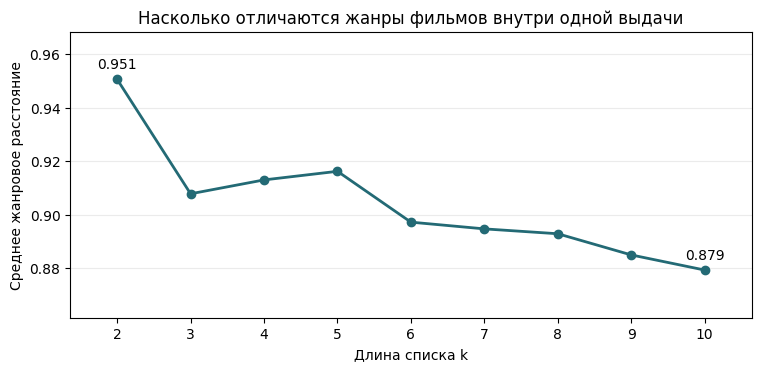

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 3.6), constrained_layout=True)
ax.plot(diversity['k'], diversity['Diversity(k)'], color='#236a75', marker='o', linewidth=2)
ax.set(xticks=range(2, K+1), xlabel='Длина списка k', ylabel='Среднее жанровое расстояние',
       title='Насколько отличаются жанры фильмов внутри одной выдачи')
ax.grid(axis='y', alpha=0.25)
for pos in (0, len(diversity)-1):
    k, val = diversity.loc[pos, ['k', 'Diversity(k)']]
    ax.annotate(f'{val:.3f}', (k, val), xytext=(0, 8), textcoords='offset points', ha='center')
ax.margins(x=.08, y=.25)
plt.show()

Посмотрим на две строки файла через названия фильмов. В первом случае известны прежние просмотры, во втором есть только ID зрителя. Для холодного зрителя все три генератора начинают с недельного топа, после этого CatBoost меняет порядок по признакам фильмов.

In [19]:
example_table = {'место': np.arange(1, K+1)}
for u in example_ids:
    label = f'{raw_users[u]} · просмотров {history.u_n[u]}'
    example_table[label] = title[examples[u]]
    if history.u_n[u]:
        fav = history.favorites(np.array([u]))[0][0]
        print(f'Зритель {raw_users[u]}: любимый жанр «{genre_names[fav]}», опорный фильм «{title[history.anchor[u]]}».')
display(pd.DataFrame(example_table))

Зритель 2: любимый жанр «прочее», опорный фильм «Монстр в Париже».


,место,2 · просмотров 49,6 · просмотров 0
0,1,Ральф против Интернета,Гнев человеческий
1,2,Монстры на каникулах 3: Море зовёт,Клиника счастья
2,3,Тайна Коко,Хрустальный
3,4,Холодное сердце II,Девятаев
4,5,Гнев человеческий,Секреты семейной жизни
5,6,Моана,Прабабушка легкого поведения
6,7,Мастер меча,Мастер меча
7,8,Суперсемейка 2,Рядовой Чээрин
8,9,В поисках Дори,Маша
9,10,Головоломка,100% волк


## 10. Что получилось

В сохранённом запуске на официальном тесте в среднем за зрительский день ранкер нашёл **26,17%** досмотренных фильмов в первых десяти местах. Недельный топ нашёл **22,22%**. NDCG@10 вырос с **0,13321 до 0,16243**. Бустинг обошёл недельный топ в обеих группах пользователей. В расчёт вошли 118 225 зрительских дней для тех, кто был в train, и 43 918 для новых зрителей.

**Жанровая гипотеза дала разный результат на двух отрезках.** На валидации персональная надбавка подняла Recall@20 с 0,2943 до 0,2962. На тесте у зрителей с историей она снизила NDCG@10 на 0,00319. У зрителей без истории списки совпали. На этих данных фиксированной прибавки за любимый жанр недостаточно, чтобы расставить первые десять фильмов. У ранкера есть дополнительная информация о популярности самого фильма и его связи с историей зрителя.

По среднему модулю SHAP первые места заняли недельная популярность фильма (0,436), скор жанрового тренда (0,422) и SVD (0,368). Средний модуль вклада нейросетевого скора составил 0,127. Признак доли досмотров основного жанра получил нулевую важность в выбранной модели. Недельная популярность входит и в формулу тренда, поэтому SHAP этих двух признаков нельзя читать как два независимых выигрыша в метрике.

Для 1 058 084 пользователей ранкер оценил 54 575 710 пар. Жанровое расстояние в десятке высокое, **Diversity(10) = 0,87936**. При этом во всех десятках вместе встретилось всего **180 фильмов**. Система может поставить рядом детектив и комедию и при этом предлагать одну и ту же популярную детективную историю многим людям. У зрителя 2 самым частым с учётом досмотров оказался жанр «прочее». В эту группу попали разные редкие жанры, поэтому по ней трудно понять вкусы конкретного человека.